# 10.4 — PCA and the Plot Boundary

**Chapter 10, sections 3.2 and 5.2** — the `plot_clustering` helper printed at §5.2 and the
projection drawn in \Cref{fig:NetflixPcaClusters}. The starting point for **Exercise 9**.

**The question this notebook answers:** where exactly is the boundary between the distributed
computation and the local plot, how much crosses it, and what does the picture on the other side
*not* show?

Sixty-five countries described by six columns — three counts of titles in the local streaming
catalogue, three monthly subscription prices. Six dimensions cannot be drawn on a plane, so PCA
reduces them to two while the data is still distributed, and only the result is collected.

**Source.** `Notebooks old/Spark-Example-22-Mllib-Clustering.ipynb`, cell 2 — the `plot_clustering`
half. The clustering half of that notebook is `07.09 Clustering Countries.ipynb`, which uses the same
six columns to make the *scaling* argument; this notebook does not repeat it, and section 5 leans on
it.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA as PCAml
from pyspark.ml.clustering import KMeans
import pyspark.sql.functions as F
import seaborn as sns
import matplotlib.pyplot as plt

DATA = os.environ.get("CS777_DATA", "../data")
SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))

spark = (SparkSession.builder
         .appName("CS777-10.4")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

COLUMNS = ["Total_Library_Size", "Num_TV_Shows", "Num_Movies",
           "Cost_Per_Month_Basic", "Cost_Per_Month_Standard", "Cost_Per_Month_Premium"]

raw = spark.read.csv(os.path.join(DATA, "netflix-subscription.csv"),
                     header=True, inferSchema=True)
data = VectorAssembler(inputCols=COLUMNS, outputCol="features").transform(raw).cache()
print(f"countries {data.count()}   feature columns {len(COLUMNS)}")


class JobCounter:
    """Count the Spark jobs submitted inside the block."""
    def __init__(self, spark):
        self.sc = spark.sparkContext
    def __enter__(self):
        self.before = self.sc.statusTracker().getJobIdsForGroup(None)
        return self
    def __exit__(self, *exc):
        self.n = len(self.sc.statusTracker().getJobIdsForGroup(None)) - len(self.before)

countries 65   feature columns 6


---

## 1. Three clusters, fitted on the six raw columns

`KMeans(k=3, seed=1)` on the assembled feature vector, exactly as the source notebook fitted it. The
vector is **not rescaled**, and that is deliberate — it is the state \Cref{fig:NetflixPcaClusters}
was drawn from, and section 5 is where changing it becomes the point.

In [2]:
model = KMeans(k=3, seed=1).fit(data)
predictions = model.transform(data).cache()

(predictions.groupBy("prediction")
 .agg(F.count("*").alias("countries"),
      *[F.round(F.avg(c), 1).alias(c) for c in COLUMNS])
 .orderBy("prediction").show(truncate=False))

+----------+---------+------------------+------------+----------+--------------------+-----------------------+----------------------+
|prediction|countries|Total_Library_Size|Num_TV_Shows|Num_Movies|Cost_Per_Month_Basic|Cost_Per_Month_Standard|Cost_Per_Month_Premium|
+----------+---------+------------------+------------+----------+--------------------+-----------------------+----------------------+
|0         |6        |3250.2            |2147.3      |1102.8    |9.6                 |13.7                   |17.6                  |
|1         |20       |6380.6            |4323.9      |2056.7    |8.3                 |12.0                   |15.4                  |
|2         |39       |5085.3            |3317.2      |1768.1    |8.2                 |11.8                   |15.4                  |
+----------+---------+------------------+------------+----------+--------------------+-----------------------+----------------------+



---

## 2. The helper, and the boundary it draws

This is the helper the chapter prints at §5.2, run as course code. Its shape is the lesson, so read
it in order:

1. **On the executors** — fit the projection on the six-column vector, then apply it. The
   high-dimensional data never moves.
2. **At the boundary** — `select` exactly three fields, then **one** `toPandas()`.
3. **On the driver** — a small pandas frame, and a plot.

The source notebook did step 2 with three separate `collect` passes over two DataFrames. §5.2's
reason for one pass is that *"each collection is an action that may trigger execution of the
preceding Spark lineage"*, so three passes can mean three executions of everything upstream.

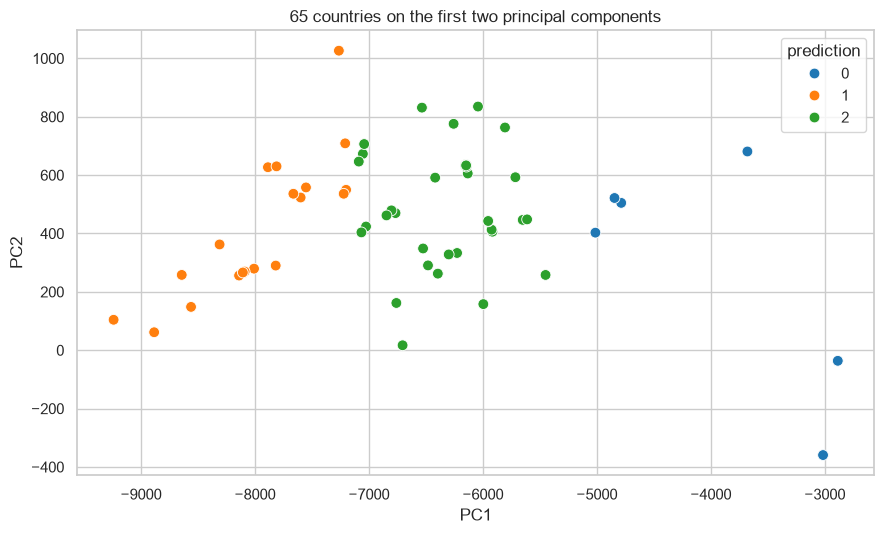

In [3]:
def plot_clustering(data, predictions, ax=None, title=None):
    # Executors: fit the projection on the six-column feature vector, then apply it.
    pca = PCAml(k=2, inputCol="features", outputCol="pca")
    pca_model = pca.fit(data)
    projected = pca_model.transform(predictions)

    # Driver: three columns of a 65-row table cross the boundary, not the features.
    small = projected.select("Country", "prediction", "pca").toPandas()
    small["x"] = small["pca"].apply(lambda v: float(v[0]))
    small["y"] = small["pca"].apply(lambda v: float(v[1]))

    sns.scatterplot(data=small, x="x", y="y", hue="prediction",
                    palette="tab10", ax=ax, s=60)
    if title:
        ax.set_title(title)
    # Label placement is a presentation detail and is omitted here.
    return pca_model, small


sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 5.5))
pca_model, small = plot_clustering(data, predictions, ax=ax,
                                  title="65 countries on the first two principal components")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

### How much actually crossed

§5.2 offers a size check — *"the product of the number of rows and columns as a rough indicator of
whether a result is appropriate to collect on a driver with 16 GB of memory"* — and a second bound
from the figure itself: once a result has more distinguishable points than the image has pixels,
further rows add nothing visible.

In [4]:
full_cols = len(predictions.columns) + len(COLUMNS) - 1   # vector counts as its 6 numbers
rows = small.shape[0]

print(f"{'':<34}{'rows':>6}{'columns':>9}{'rows x cols':>13}{'bytes':>10}")
print(f"{'left on the executors':<34}{rows:>6}{full_cols:>9}{rows * full_cols:>13}"
      f"{'--':>10}")
print(f"{'crossed to the driver':<34}{rows:>6}{3:>9}{rows * 3:>13}"
      f"{small[['Country', 'prediction', 'pca']].memory_usage(deep=True).sum():>10,}")
print(f"\nA 900 x 550 figure has {900 * 550:,} pixels for {rows} points, so the plot is nowhere")
print("near its own resolution limit. At this scale the boundary costs nothing -- which is")
print("why 5.2 says the ORDER of these operations is what matters as the data grows, and")
print("not the saving on 65 rows.")

                                    rows  columns  rows x cols     bytes
left on the executors                 65       15          975        --
crossed to the driver                 65        3          195     7,721

A 900 x 550 figure has 495,000 pixels for 65 points, so the plot is nowhere
near its own resolution limit. At this scale the boundary costs nothing -- which is
why 5.2 says the ORDER of these operations is what matters as the data grows, and
not the saving on 65 rows.


### One pass or three, checked rather than asserted

The claim in the caption is that the chapter's helper makes one `collect` pass where the source
notebook's made three. Spark counts its own jobs, so the claim is checkable.

In [5]:
pca_fitted = PCAml(k=2, inputCol="features", outputCol="pca").fit(data)
projected = pca_fitted.transform(predictions).cache(); projected.count()

with JobCounter(spark) as one:
    df = projected.select("Country", "prediction", "pca").toPandas()
print(f"the chapter's helper -- one select, one toPandas : {one.n} job(s)")

with JobCounter(spark) as three:
    xs = projected.rdd.map(lambda r: r.pca).collect()
    cl = projected.rdd.map(lambda r: r.prediction).collect()
    co_ = projected.rdd.map(lambda r: r.Country).collect()
print(f"the source notebook -- three rdd.map().collect() : {three.n} job(s)")

# The two agree on the answer; they differ only in what they cost.
assert [float(v[0]) for v in xs] == list(df["pca"].apply(lambda v: float(v[0])))
assert cl == list(df["prediction"]) and co_ == list(df["Country"])
print("\nboth routes produce identical values -- asserted above")

the chapter's helper -- one select, one toPandas : 1 job(s)


the source notebook -- three rdd.map().collect() : 3 job(s)

both routes produce identical values -- asserted above


### And `fit` is not one pass

The chapter's listing carries the comment `# one distributed pass, to find the axes` beside
`pca.fit(data)`. The same job counter can check it.

In [6]:
data.count()                      # make sure the cache is warm, so we count only the fit
with JobCounter(spark) as fit_jobs:
    PCAml(k=2, inputCol="features", outputCol="pca").fit(data)
print(f"PCAml.fit submitted {fit_jobs.n} Spark jobs")

st = spark.sparkContext.statusTracker()
print("\nFitting PCA means building the covariance matrix and then decomposing it, and")
print("Spark does that in several jobs rather than one scan. The decomposition itself")
print("happens on the driver -- the 6x6 covariance matrix is tiny -- but getting to it")
print(f"is {fit_jobs.n} jobs, not one pass. The transform that follows IS a single")
print("narrow pass, and it is the half that stays distributed.")

with JobCounter(spark) as tr_jobs:
    pca_fitted.transform(predictions).count()
print(f"\nby comparison, transform + count: {tr_jobs.n} job(s)")

PCAml.fit submitted 5 Spark jobs

Fitting PCA means building the covariance matrix and then decomposing it, and
Spark does that in several jobs rather than one scan. The decomposition itself
happens on the driver -- the 6x6 covariance matrix is tiny -- but getting to it
is 5 jobs, not one pass. The transform that follows IS a single
narrow pass, and it is the half that stays distributed.

by comparison, transform + count: 2 job(s)


---

## 3. The number §3.2 asks for and the figure does not carry

§3.2: *"There is no universally correct number of components to retain, so the explained variance
should be reported and considered when interpreting the resulting projection."*

\Cref{fig:NetflixPcaClusters} does not report it. Spark's `PCAModel` has it.

In [7]:
ev = pca_model.explainedVariance
print(f"PC1 explains {ev[0]:9.4%} of the variance")
print(f"PC2 explains {ev[1]:9.4%}")
print(f"together      {sum(ev):9.4%}  -- so the plane loses almost nothing\n")

print("PC1's loadings, which say what that variance is made of:")
for i, c in enumerate(COLUMNS):
    bar = "#" * int(abs(pca_model.pc[i, 0]) * 40)
    print(f"  {c:<26}{pca_model.pc[i, 0]:>9.4f}  {bar}")

PC1 explains  96.4882% of the variance
PC2 explains   3.5101%
together       99.9983%  -- so the plane loses almost nothing

PC1's loadings, which say what that variance is made of:
  Total_Library_Size          -0.7903  ###############################
  Num_TV_Shows                -0.5729  ######################
  Num_Movies                  -0.2174  ########
  Cost_Per_Month_Basic         0.0001  
  Cost_Per_Month_Standard      0.0001  
  Cost_Per_Month_Premium       0.0002  


99.99% of the variance in two dimensions looks like an excellent projection, and it is the **least**
informative number in this notebook. The loadings say why: the three price columns have loadings of
about 0.0001, which is zero to four decimal places. **PC1 is the catalogue size**, and the variance it
explains is overwhelming because catalogue sizes run into the thousands while prices run from about
two to twenty-seven. Variance is not scale-free, so the projection is measuring the units.

This is §3.2's warning arriving in the form of a reassuring statistic: *"variables measured on larger
numerical scales can dominate the resulting components even when their apparent importance is
primarily a consequence of their units."*

In [8]:
print(f"{'column':<26}{'min':>10}{'max':>10}{'range':>10}")
for c in COLUMNS:
    r = raw.select(F.min(c).alias("lo"), F.max(c).alias("hi")).first()
    print(f"{c:<26}{r['lo']:>10.2f}{r['hi']:>10.2f}{r['hi'] - r['lo']:>10.2f}")

column                           min       max     range


Total_Library_Size           2274.00   7325.00   5051.00
Num_TV_Shows                 1675.00   5234.00   3559.00
Num_Movies                    373.00   2387.00   2014.00


Cost_Per_Month_Basic            1.97     12.88     10.91


Cost_Per_Month_Standard         3.00     20.46     17.46
Cost_Per_Month_Premium          4.02     26.96     22.94


### Exercise 9(a) — why the axes have such different extents

Exercise 9(a) quotes the axis ranges from the figure and asks what the difference in scale says. The
projection is in hand, so the ranges can be read rather than estimated.

In [9]:
print(f"PC1 (horizontal): {small['x'].min():10.1f} to {small['x'].max():10.1f}"
      f"   span {small['x'].max() - small['x'].min():8.1f}")
print(f"PC2 (vertical):   {small['y'].min():10.1f} to {small['y'].max():10.1f}"
      f"   span {small['y'].max() - small['y'].min():8.1f}")
span_ratio = ((small['x'].max() - small['x'].min())
              / (small['y'].max() - small['y'].min()))
var_ratio = ev[0] / ev[1]
print(f"\nratio of spans                {span_ratio:6.1f} to 1")
print(f"ratio of explained variances  {var_ratio:6.1f} to 1")
print(f"square root of that           {var_ratio ** 0.5:6.1f} to 1   <- the one to compare")
print("A variance is a squared quantity, so a span scales with its square root.")

# Both coordinates are far from zero, which is worth a sentence of its own: Spark
# derives the components from the covariance matrix, which IS mean-centred, but
# `transform` projects the raw vector WITHOUT subtracting the mean. So the cloud sits
# wherever the untranslated projection puts it, not around the origin.
means = raw.select(*[F.avg(c).alias(c) for c in COLUMNS]).first()
offset = sum(means[c] * pca_model.pc[i, 0] for i, c in enumerate(COLUMNS))
print(f"\nprojection of the mean country onto PC1: {offset:.1f}")
print(f"mean of the plotted PC1 values:          {small['x'].mean():.1f}")
print("They agree, which confirms transform() does not centre -- the offset is real,")
print("not an artefact, and it is why no point is near x = 0.")

PC1 (horizontal):    -9241.8 to    -2886.9   span   6354.9
PC2 (vertical):       -359.2 to     1026.4   span   1385.6

ratio of spans                   4.6 to 1
ratio of explained variances    27.5 to 1
square root of that              5.2 to 1   <- the one to compare
A variance is a squared quantity, so a span scales with its square root.



projection of the mean country onto PC1: -6606.1
mean of the plotted PC1 values:          -6606.1
They agree, which confirms transform() does not centre -- the offset is real,
not an artefact, and it is why no point is near x = 0.


---

## 4. Exercise 9(b) — the one change that alters the picture most

Exercise 9(b) asks for the single modification with the largest effect. It is not the number of
clusters, the seed, or `k`: it is **standardising the six columns before either K-means or PCA sees
them**. `StandardScaler` divides each column by its standard deviation, so a dollar of price counts
as much as a title of catalogue.

Everything else below is held fixed — same data, same `k`, same seed, same helper.

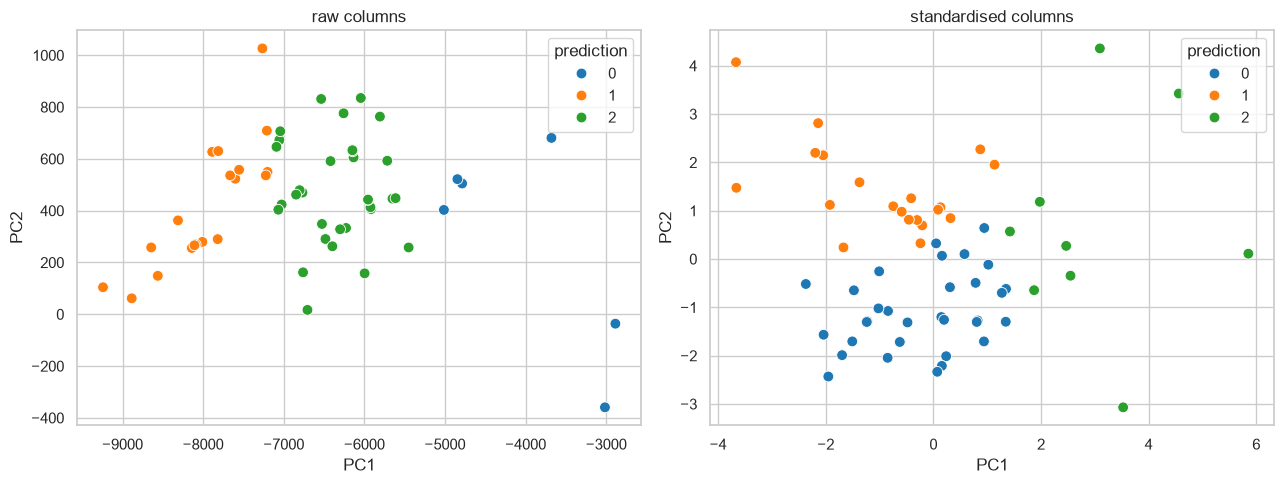

In [10]:
scaler = StandardScaler(inputCol="features", outputCol="scaled",
                        withMean=True, withStd=True).fit(data)
scaled = (scaler.transform(data)
          .drop("features").withColumnRenamed("scaled", "features").cache())

scaled_model = KMeans(k=3, seed=1).fit(scaled)
scaled_pred = scaled_model.transform(scaled).cache()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_clustering(data, predictions, ax=axes[0], title="raw columns")
pca_scaled, small_scaled = plot_clustering(scaled, scaled_pred, ax=axes[1],
                                           title="standardised columns")
for a in axes:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [11]:
ev2 = pca_scaled.explainedVariance
print(f"{'':<20}{'PC1':>10}{'PC2':>10}{'together':>12}")
print(f"{'raw columns':<20}{ev[0]:>10.2%}{ev[1]:>10.2%}{sum(ev):>12.2%}")
print(f"{'standardised':<20}{ev2[0]:>10.2%}{ev2[1]:>10.2%}{sum(ev2):>12.2%}")

print(f"\nPC1 loadings, raw vs standardised:")
print(f"{'column':<26}{'raw':>10}{'standardised':>14}")
for i, c in enumerate(COLUMNS):
    print(f"{c:<26}{pca_model.pc[i, 0]:>10.4f}{pca_scaled.pc[i, 0]:>14.4f}")

print(f"\ncluster sizes  raw {sorted(r['count'] for r in predictions.groupBy('prediction').count().collect())}"
      f"   standardised {sorted(r['count'] for r in scaled_pred.groupBy('prediction').count().collect())}")

                           PC1       PC2    together
raw columns             96.49%     3.51%     100.00%
standardised            50.04%    41.74%      91.78%

PC1 loadings, raw vs standardised:
column                           raw  standardised
Total_Library_Size           -0.7903       -0.3559
Num_TV_Shows                 -0.5729       -0.3093
Num_Movies                   -0.2174       -0.3828
Cost_Per_Month_Basic          0.0001        0.4456
Cost_Per_Month_Standard       0.0001        0.4679
Cost_Per_Month_Premium        0.0002        0.4621

cluster sizes  raw [6, 20, 39]   standardised [9, 22, 34]


Two things changed, and the second is the one that matters. The explained variance **fell** — two
components now carry much less of the total, because there are genuinely more than two directions of
variation once the prices are allowed to contribute. And the loadings spread out: PC1 is no longer one
column wearing a principal component's name.

The projection that reported 99.99% was the less faithful of the two. A high explained variance means
the two retained directions capture most of the *variance as measured in the given units*, which is a
statement about the units whenever the units differ by three orders of magnitude.

*(Cluster labels are arbitrary integers, so the sizes are comparable between the two fits but the
label numbers are not — a country in cluster 0 on the left may be in cluster 2 on the right without
having moved.)*

---

## 5. Exercise 9(c) — what the overlap does and does not mean

\Cref{fig:NetflixPcaClusters}'s caption says two of the three clusters *"overlap heavily in this
projection, which is evidence that they are close in the two retained directions and not evidence
that they are close in the data."*

With only two of six directions retained there is no way to tell from the picture. But the centroids
are in hand in both spaces, so the two distances can simply be compared.

In [12]:
import itertools, math

centres = model.clusterCenters()                       # in the 6-column raw space
pcs = [[pca_model.pc[i, j] for i in range(len(COLUMNS))] for j in range(2)]

def project(v):
    return [sum(v[i] * pcs[j][i] for i in range(len(v))) for j in range(2)]

print(f"{'pair':<10}{'distance in 6-D':>18}{'distance in the plane':>24}{'kept':>12}")
for a, b in itertools.combinations(range(3), 2):
    d6 = math.dist(centres[a], centres[b])
    d2 = math.dist(project(centres[a]), project(centres[b]))
    print(f"{f'{a} vs {b}':<10}{d6:>18.2f}{d2:>24.2f}{d2 / d6:>11.4%}")

print("\nThe plane keeps essentially ALL of the separation between these centroids --")
print("which is not reassurance, it is the same finding again. The centroids differ")
print("mostly in catalogue size, PC1 IS catalogue size, so of course the projection")
print("preserves the distance. What CANNOT be concluded from the picture is this")
print("table: it had to be computed in the full space to be known at all.")

pair         distance in 6-D   distance in the plane        kept
0 vs 1               3930.21                 3930.21  100.0000%
0 vs 2               2275.67                 2275.67  100.0000%
1 vs 2               1665.70                 1665.70  100.0000%

The plane keeps essentially ALL of the separation between these centroids --
which is not reassurance, it is the same finding again. The centroids differ
mostly in catalogue size, PC1 IS catalogue size, so of course the projection
preserves the distance. What CANNOT be concluded from the picture is this
table: it had to be computed in the full space to be known at all.


In [13]:
# The quantity Exercise 9(c) asks for: how much of each country's own variation
# survives the projection. Reconstruct from two components and measure the residual.
def reconstruct_error(row):
    v = list(row["features"])
    p = project(v)
    back = [sum(p[j] * pcs[j][i] for j in range(2)) for i in range(len(v))]
    return math.dist(v, back) / (math.dist(v, [0] * len(v)) or 1.0)

errs = [reconstruct_error(r) for r in data.select("features").collect()]
print(f"residual after keeping 2 of 6 components, as a fraction of each country's vector:")
print(f"  smallest {min(errs):.4%}   median {sorted(errs)[len(errs) // 2]:.4%}"
      f"   largest {max(errs):.4%}")
print("\nSmall -- on the RAW columns, where the discarded directions are the price")
print("columns and the price columns are numerically tiny. That is the same fact as")
print("the 99.99%, and it is the same trap: the residual is small in dollars because")
print("dollars are small, not because the prices did not matter.")

residual after keeping 2 of 6 components, as a fraction of each country's vector:
  smallest 0.1733%   median 0.3930%   largest 1.0900%

Small -- on the RAW columns, where the discarded directions are the price
columns and the price columns are numerically tiny. That is the same fact as
the 99.99%, and it is the same trap: the residual is small in dollars because
dollars are small, not because the prices did not matter.


---

## What this measured

**The boundary is one `select` and one `toPandas`, and at this scale it is free.** Three columns of a
65-row table crossed; the six-column feature vectors did not. The order of the operations is what
§5.2 is teaching, because the same two lines in the other order — collect, then reduce — is the
out-of-memory failure the section opens with. Sixty-five rows cannot demonstrate the failure, which
is why the notebook reports the rows-times-columns check rather than a timing.

**`pca.fit` is not "one distributed pass", and the chapter's listing says it is.** Spark's own job
counter puts the fit at five jobs: building a covariance matrix and decomposing it is not a single scan.
The `transform` that follows *is* one narrow pass, and it is the half the chapter's argument actually
needs — the projection stays distributed. The comment is attached to the wrong line.

**One `collect` pass rather than three, confirmed by Spark's own job count.** The source notebook's
three `rdd.map().collect()` calls and the chapter's single `select().toPandas()` return identical
values — asserted in section 2 — at different costs in submitted jobs.

**The explained variance is 99.99%, and it is the most misleading number here.** PC1's loadings on the
three price columns are 0.0001. The projection that looks nearly lossless is nearly lossless *in the
units it was given*, where catalogue sizes are thousands and prices are single digits. §3.2 says to
report the explained variance; this notebook is the reason to report the **loadings** beside it.

**Exercise 9(a)'s axis ranges are reproduced, and they carry a second fact.** PC1 spans about −9,240
to −2,890 and PC2 about −360 to 1,030 — a ratio of roughly 4.6 to 1, which is the *square root* of the
27.5-to-1 ratio of explained variances rather than the ratio itself, because a variance is a squared
quantity and a span is not. Neither
range straddles zero, and the cell shows why: Spark derives the components from the centred covariance
matrix but `transform` projects the *raw* vector, so the whole cloud is offset by the projection of
the mean — which the notebook verifies by computing that offset and matching it to the plotted mean.

**Exercise 9(b)'s answer is standardisation, and it makes the projection honest by making it look
worse.** Same data, same `k`, same seed: the explained variance falls and the loadings spread across
all six columns. A six-dimensional dataset that genuinely needs more than two dimensions now says so.

**Exercise 9(c): the overlap cannot be read from the picture, and the table that settles it has to be
computed in the full space.** Centroid distances in six dimensions against the same distances in the
plane show the plane keeping essentially *all* of the separation — which reads as reassurance and is
not, because the centroids differ mostly in catalogue size and PC1 is catalogue size. The residual
check says the same thing a third time: small residuals on the raw columns mean the discarded
directions were the price columns, and price columns are numerically small. Three statistics, one
fact, and the fact is about the units.